# Tutorial: Xenium Centroids to Lumen (scores)

Here we take some data from the recent preprint, {cite}`Singhal2026.07.13.738221`. Data will be uploaded for general use in time.

We will see how to use the auto settings and how they might be better than the defaults from {cite}`Reyes2026`.

In [1]:
%load_ext autoreload
%autoreload 2

import anndata as ad
from seq_lumen import Quantifier
from anndata.acc import A
import numpy as np
import matplotlib.pyplot as plt

In [2]:
adata_full = ad.read_h5ad(
    "/data1/peerd/roses3/basal_ablation/data/processed/xenium/compiled_adata/BA_processed_segger_pub_20260621.h5ad"
)

In [11]:
sample_id = adata_full[adata_full.obs["condition"] == "control"].obs["sample_id"].cat.categories[-3]
adata = adata_full[adata_full.obs["sample_id"] == sample_id]

In [12]:
adata.obs["is_epithelial"] = (adata.obs["cell_annotation_coarse"] == "Normal Epithelial") | (
    adata.obs["cell_annotation_coarse"] == "Cancer_epithelial"
)
centroids_acc = A.obsm["X_spatial"]
border_acc = A.obs["is_epithelial"]
centroids = adata[centroids_acc]
border_centroids = adata[adata[border_acc]][centroids_acc]

/tmp/ipykernel_2097111/2242219274.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["is_epithelial"] = (adata.obs["cell_annotation_coarse"] == "Normal Epithelial") | (



## Parameter Choice

The default parameters of {class}`~seq_lumen.Quantifier` are those from {cite}`Reyes2026`.

We offer a small auto-discovery method, though, that may align better with user expectations. It also contains a small fix for not calling luminal areas on the outer boundary of the sample. This is available via a `exclude_outside` setting if creating a {class}`~seq_lumen.Quantifier` manually.

First, we try the defaults from the original paper on a single sample, although {class}`~seq_lumen.Quantifier`'s {meth}`~seq_lumen.Quantifier.find`, {meth}`~seq_lumen.Quantifier.count`, {meth}`~seq_lumen.Quantifier.assign`, and {meth}`~seq_lumen.Quantifier.run` each offer the ability to loop through multiple samples at once via their `sample_acc` argument.

100%|██████████| 5/5 [00:05<00:00,  1.15s/it]


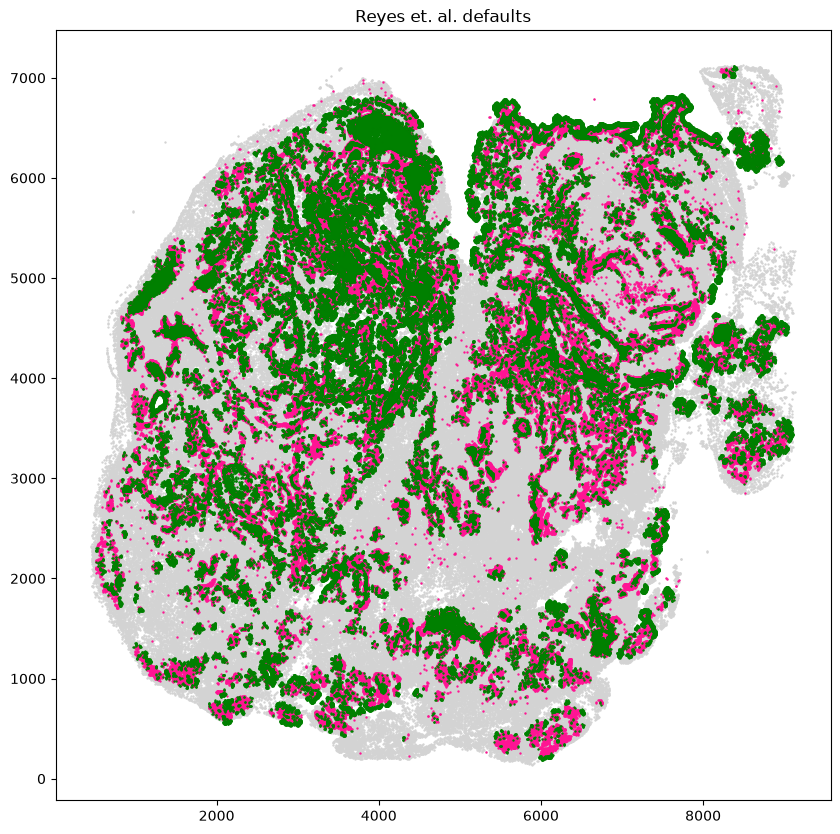

In [13]:
sl_default = Quantifier()
lumen_default = sl_default.find(adata, centroids_acc=centroids_acc, border_acc=border_acc)
plt.figure(figsize=[10, 10])
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, c="lightgray")
plt.scatter(border_centroids[:, 0], border_centroids[:, 1], s=0.5, c="deeppink")
plt.scatter(lumen_default[:, 0], lumen_default[:, 1], s=0.5, c="green")
plt.title("Reyes et. al. defaults")
plt.show()

Now, {meth}`~seq_lumen.Quantifier.from_adata` will autodiscover the underlying params for lumen identification based on properties of the centroids from _all available samples_ as this enables more unbiased cross-sample identification/comparison.

/tmp/ipykernel_2097111/1692432540.py:1: UserWarning: interpoint_distance is 7.3 (median), but these sections differ by more than 20%: {'9__0084881_Region_1': 8.9}. Check them before comparing lumen across sections.
  sl_auto = Quantifier.from_adata(
100%|██████████| 5/5 [00:00<00:00, 10.14it/s]


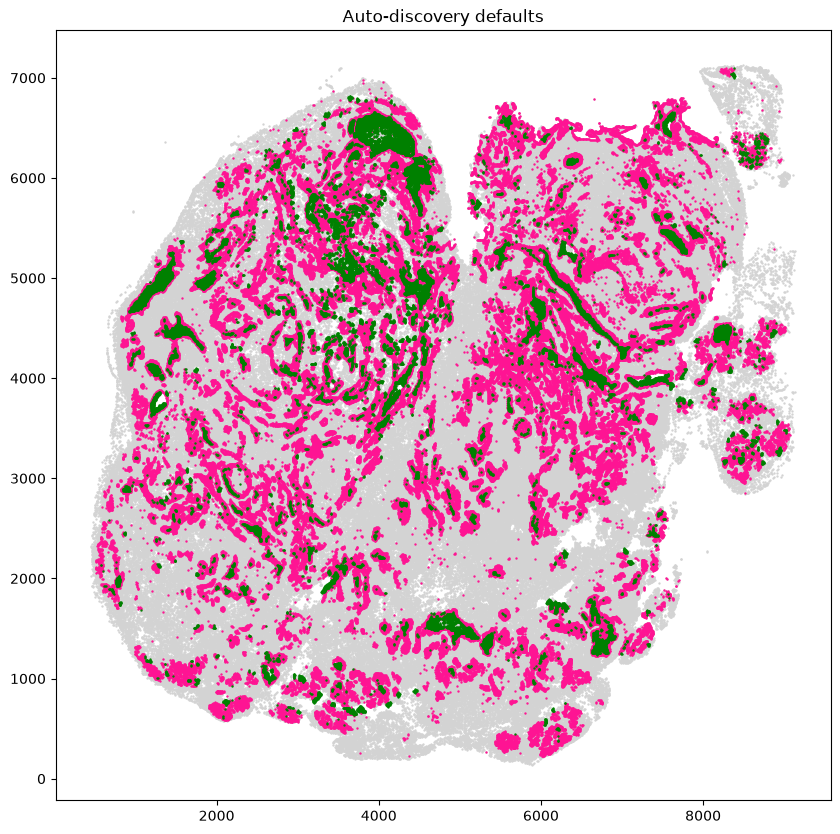

In [14]:
sl_auto = Quantifier.from_adata(
    adata_full,
    centroids_acc=centroids_acc,
    sample_acc=A.obs["sample_id"],
)
lumen_auto = sl_auto.find(adata, centroids_acc=centroids_acc, border_acc=border_acc)
plt.figure(figsize=[10, 10])
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, c="lightgray")
plt.scatter(border_centroids[:, 0], border_centroids[:, 1], s=0.5, c="deeppink")
plt.scatter(lumen_auto[:, 0], lumen_auto[:, 1], s=0.5, c="green")
plt.title("Auto-discovery defaults")
plt.show()

Users are likely more interested in a final "score" they can correlate with types and features.

It seems that the auto-discovered parameters are a bit more sensitive to the sparsity in the middle of the slide.

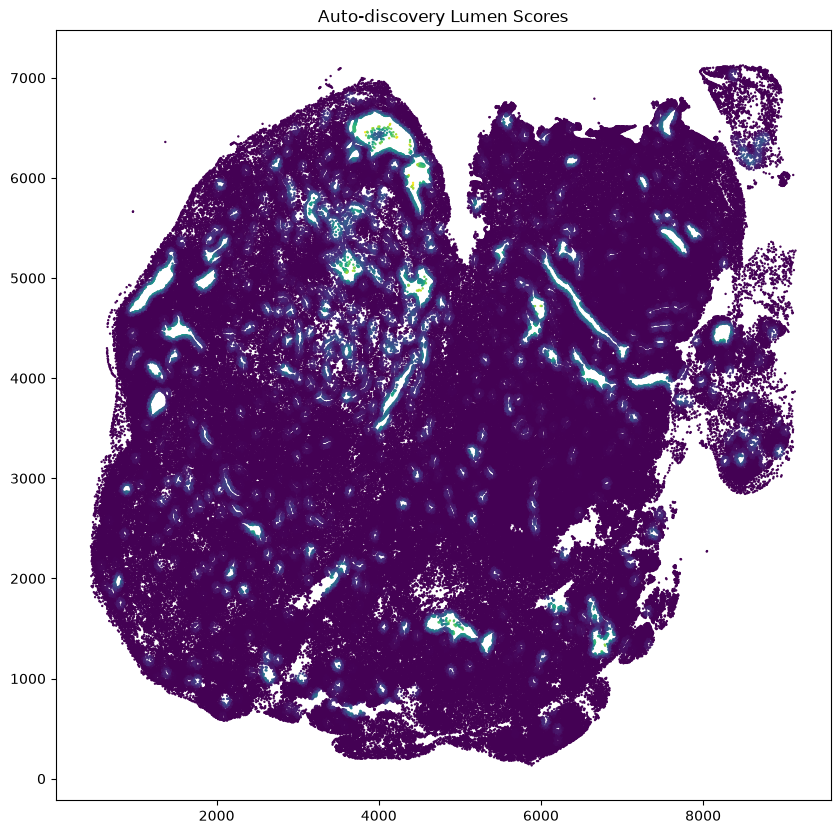

In [15]:
count_acc = A.obs["lumen_score_auto"]
sl_auto.count(adata, lumen_auto, centroids_acc=centroids_acc, count_acc=count_acc)
plt.figure(figsize=[10, 10])
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, c=np.array(adata[count_acc]))
plt.title("Auto-discovery Lumen Scores")
plt.show()

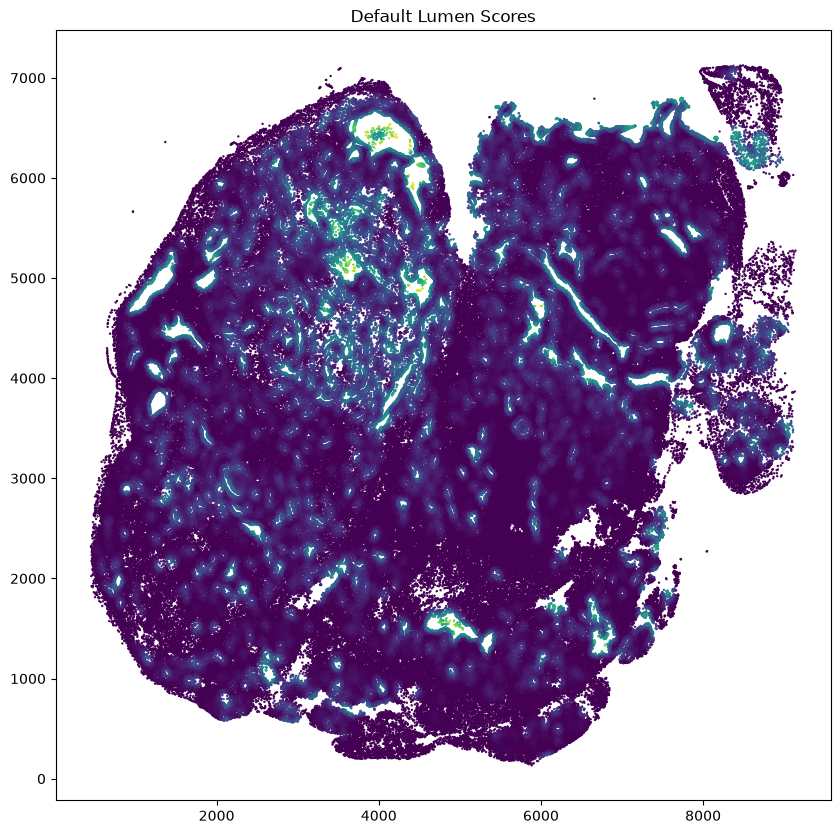

In [16]:
count_acc = A.obs["lumen_score_default"]
sl_default.count(adata, lumen_default, centroids_acc=centroids_acc, count_acc=count_acc)
plt.figure(figsize=[10, 10])
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, c=np.array(adata[count_acc]))
plt.title("Default Lumen Scores")
plt.show()

Finally, users may be interested in which lumen a given cell borders.

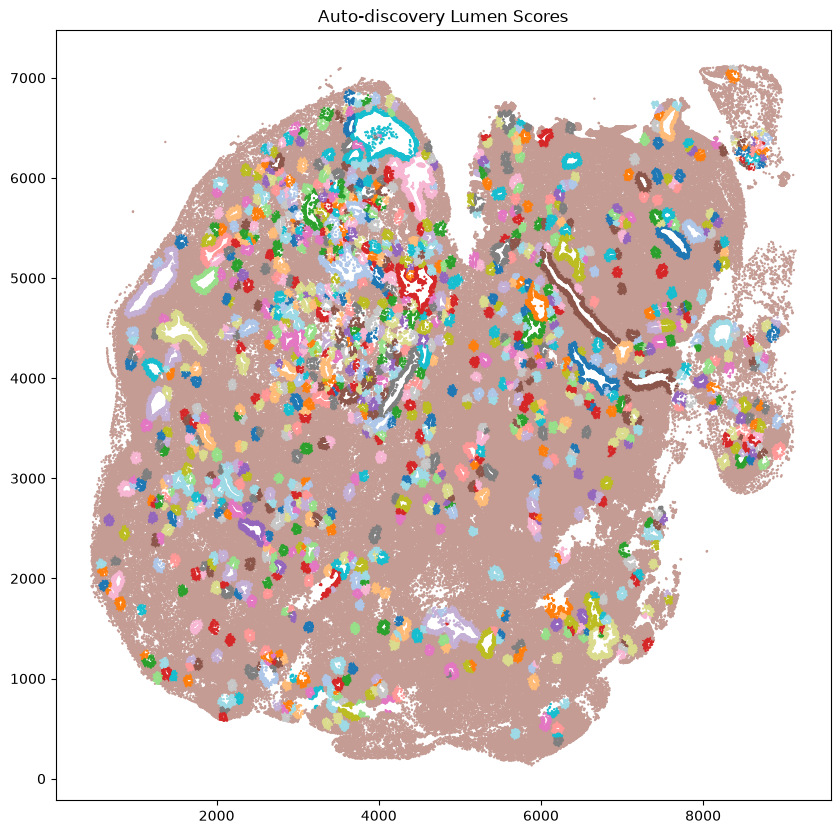

In [17]:
assignment_acc = A.obs["lumen_id_auto"]
sl_auto.assign(adata, lumen_auto, centroids_acc=centroids_acc, assignment_acc=assignment_acc)
plt.figure(figsize=[10, 10])
colors = np.array(adata[assignment_acc])
unique_colors = np.unique(colors)
for c in np.unique(colors):
    colors[colors == c] = np.random.randint(sum(unique_colors))
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, cmap="tab20", c=colors)
plt.title("Auto-discovery Lumen Scores")
plt.show()

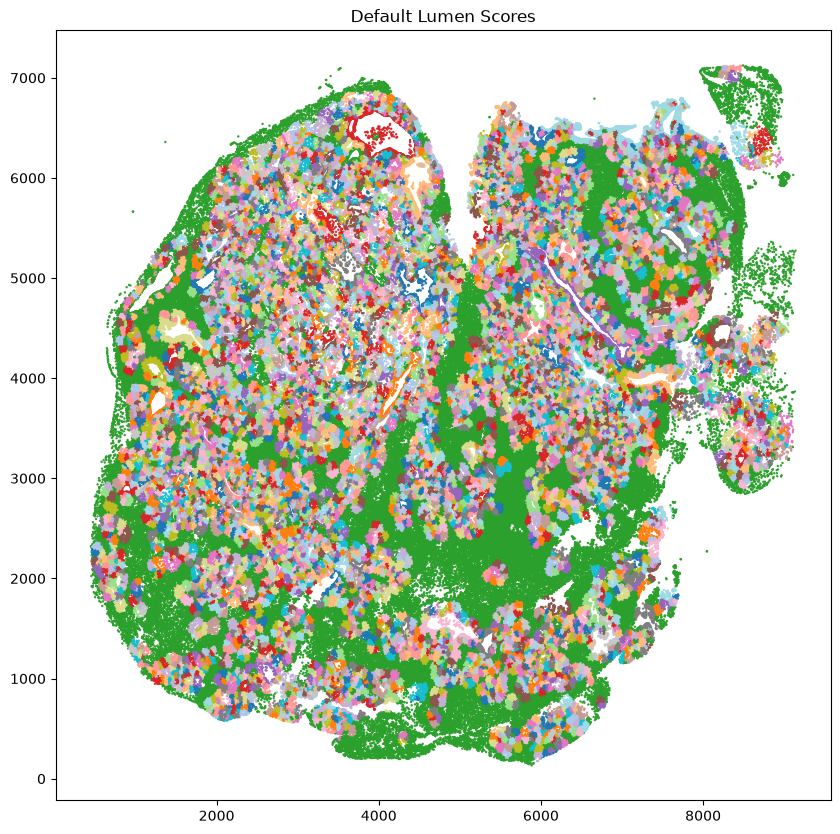

In [18]:
assignment_acc = A.obs["lumen_id_default"]
sl_default.assign(adata, lumen_default, centroids_acc=centroids_acc, assignment_acc=assignment_acc)
plt.figure(figsize=[10, 10])
colors = np.array(adata[assignment_acc])
unique_colors = np.unique(colors)
for c in np.unique(colors):
    colors[colors == c] = np.random.randint(sum(unique_colors))
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, cmap="tab20", c=colors)
plt.title("Default Lumen Scores")
plt.show()

Users are likely more interested in a final "score" they can correlate with types and features.

It seems that the auto-discovered parameters are a bit more sensitive to the sparsity in the middle of the slide.